# Lecture 2: Linear Algebra for Quantum Computing

[Course contents](../00_course_contents.md) | [← Previous lecture](./01_introduction_and_python.ipynb) | [Next lecture →](./03_complex_numbers_and_operators.ipynb) | [Supplementary lecture](./13_quantum_technology_roadmaps_and_ai.ipynb)

> **Open course material.** You may download, teach, adapt, and share this notebook with attribution. It can serve a course at any institution, independent study, exam review, or preparation for work in quantum technology. See the [reuse terms](../LICENSE), the [teaching and self-study guide](../TEACHING_AND_SELF_STUDY.md), and the [citation metadata](../CITATION.cff).

## Learning objectives

- Work with complex vector spaces, inner products, orthonormal bases, and projectors.
- Distinguish element-wise, matrix, outer, and tensor products.
- Solve linear systems and analyze Hermitian matrices with numerically stable methods.

## Core ideas

- The inner product gives a vector space its geometry. Norms, angles, orthogonality, overlaps, and probabilities all come from it, and for complex vectors it conjugates the first vector.
- Matrix, outer, and tensor products have different shapes and different physical roles, so it matters which one a formula uses.
- Numerical methods should use the structure of a matrix: a Hermitian eigensolver and the condition number reveal information that a generic solver can hide.


## Software environment

The course uses the pinned packages in [`requirements.txt`](../requirements.txt). If they are not installed in the active Jupyter kernel, run:

```python
%pip install -r ../requirements.txt
```

Restart the kernel after installation. The next cell contains every library import required by this lecture; the notebook does not depend on variables or imports created by another lecture.

In [1]:
# Complete imports for this lecture.
from qiskit.visualization import plot_bloch_vector
import numpy as np
import matplotlib.pyplot as plt
import sympy as sy
from IPython.display import display

In [2]:
%matplotlib inline

In [3]:
A_scalar = 4
B_scalar = 2

print("product:", A_scalar * B_scalar)
print("sum:", A_scalar + B_scalar)
print("ratio:", (A_scalar - B_scalar) / (A_scalar + B_scalar))

product: 8
sum: 6
ratio: 0.3333333333333333


## Why quantum computing is written in linear algebra

For a finite quantum system, a chosen basis turns states into complex vectors and physical transformations into matrices. A normalized $n$-qubit state has $2^n$ complex components, a gate is a linear map on those components, and a measurement probability is obtained from an inner product. The abstract formulation does not depend on a basis; the matrices are only coordinate representations of the vectors and linear maps.


## Vectors and dual vectors

A ket $|\psi\rangle$ is a vector in a complex vector space. Its associated bra is the conjugate-transposed dual vector,

$$
\langle\psi|=|\psi\rangle^\dagger.
$$

Superposition follows from linearity: if $u$ and $v$ belong to the space, then so does $\alpha u+\beta v$. Entanglement is a different concept; it concerns vectors in a tensor-product space that cannot be factored into subsystem states.


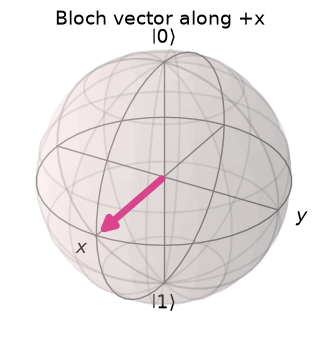

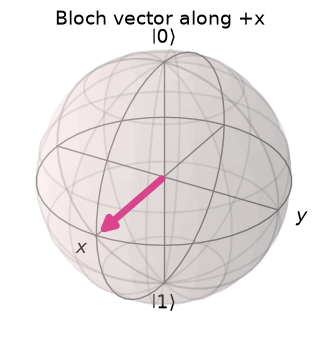

In [4]:
fig = plot_bloch_vector(
    [1, np.pi / 2, 0],
    figsize=(3, 3),
    coord_type="spherical",
    title="Bloch vector along +x",
    font_size=14,
)
display(fig)

*The Bloch vector points along $+x$, representing the qubit state $|+\rangle=(|0\rangle+|1\rangle)/\sqrt{2}$ rather than the computational-basis state $|0\rangle$.*


### Complex vector spaces

A vector space $V$ over a field $\mathbb F$ has vector addition and scalar multiplication satisfying closure, associativity, commutativity of addition, additive identity and inverses, distributivity, compatibility of scalar multiplication, and $1v=v$. Quantum state spaces use $\mathbb F=\mathbb C$.

Facts such as $0v=0$ and $\alpha 0=0$ follow from these axioms and need not be assumed separately.


**Problem:**

> Given vectors $\mathbf{v}$ and $\mathbf{u}$, and scalar $\alpha$:
> $$\mathbf{v} = \begin{bmatrix} 3 \\ 1 \end{bmatrix}, \quad \mathbf{u} = \begin{bmatrix} 2 \\ 4 \end{bmatrix}, \quad \alpha = 5$$

> Operations:
> 1. $\alpha \mathbf{u} = 5 \cdot \begin{bmatrix} 2 \\ 4 \end{bmatrix} = \begin{bmatrix} 10 \\ 20 \end{bmatrix}$ 
> 2. $\alpha \mathbf{v} + \mathbf{u} = 5\begin{bmatrix} 3 \\ 1 \end{bmatrix} + \begin{bmatrix} 2 \\ 4 \end{bmatrix} = \begin{bmatrix} 17  \\ 9 \end{bmatrix}$


In [5]:
# The same using numpy:

v = np.array([3,1])
u = np.array([2,4])
alpha = 5

print(alpha*u)
print(alpha*v + u)

[10 20]
[17  9]


In [6]:
# A one-dimensional NumPy array has shape (3,); it does not encode
# a row-versus-column orientation.
vect_1 = np.array([1, 2, 3])
vect_2 = np.array([3, 4, 5], dtype=complex)

print(vect_1)
print(vect_2)
print(vect_1 + vect_2)

[1 2 3]
[3.+0.j 4.+0.j 5.+0.j]
[4.+0.j 6.+0.j 8.+0.j]


In [7]:
# Vertical vectors (columns):

vect_col = np.array([[1],[2],[3]])
print(vect_col)

[[1]
 [2]
 [3]]


In [8]:
# Matrices

matr = np.array([[1, 2, 3],[4, 5, 6],[7, 8, 9]])
print(matr)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


In [9]:
C1 = 2*vect_1
C2 = 2*vect_col

print(C1)

print(C2)

[2 4 6]
[[2]
 [4]
 [6]]


### Linear independence

Vectors $v_1,\ldots,v_k$ are linearly independent if

$$
\alpha_1v_1+\cdots+\alpha_kv_k=0
$$

implies $\alpha_1=\cdots=\alpha_k=0$. Equivalently, none of the vectors can be written as a linear combination of the others.


**Example: two linearly independent vectors in the plane**

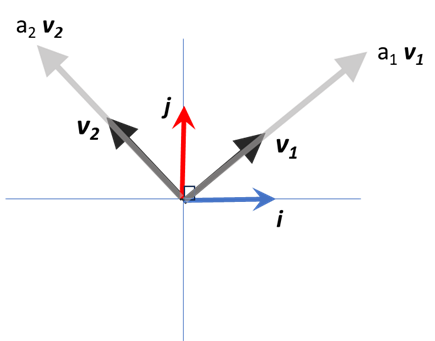

*The two gray arrows point in different directions, so neither is a scalar multiple of the other; together they form a linearly independent pair in the plane.*


**Problem:**

> Given vectors $\mathbf{v}_1$ and $\mathbf{v}_2$:
$$ \mathbf{v}_1 = \begin{bmatrix} 1 \\ 2 \end{bmatrix}, \quad \mathbf{v}_2 = \begin{bmatrix} 2 \\ 4 \end{bmatrix} $$
Are these vectors linearly independent?

> To determine if $\mathbf{v}_1$ and $\mathbf{v}_2$ are linearly independent, solve for $\alpha$ and $\beta$ in the equation:
$$ \alpha \mathbf{v}_1 + \beta \mathbf{v}_2 = \mathbf{0} $$


> Given the equation:
$$ \alpha \begin{bmatrix} 1 \\ 2 \end{bmatrix} + \beta \begin{bmatrix} 2 \\ 4 \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \end{bmatrix} $$
This simplifies to:
$$ \begin{cases} 
\alpha + 2\beta = 0 \\
2\alpha + 4\beta = 0 
\end{cases} $$
Both equations give the same condition:
$$ \begin{cases} 
\alpha = -2\beta \\
\alpha = -2\beta 
\end{cases} $$
Any pair with $\alpha = -2\beta$, for example $\alpha=-2$ and $\beta=1$, solves the system. A nonzero solution exists, so $\mathbf{v}_1$ and $\mathbf{v}_2$ are linearly dependent; indeed, $\mathbf{v}_2=2\mathbf{v}_1$.


In [10]:
vectors = np.array([[1, 2], [2, 4]], dtype=float)
rank = np.linalg.matrix_rank(vectors)

print("rank:", rank)
print("linearly independent:", rank == vectors.shape[1])

rank: 1
linearly independent: False


### Dimension and bases

The dimension of a finite-dimensional vector space is the number of vectors in any basis. Equivalently, it is the maximum size of a linearly independent set. Infinite-dimensional spaces require a more careful notion of basis and convergence.


A **basis** is a linearly independent set that spans the space. A basis need not contain unit vectors. An **orthonormal basis** $\{e_i\}$ additionally satisfies

$$
\langle e_i|e_j\rangle=\delta_{ij}.
$$

Every vector in an $n$-dimensional space has a unique expansion

$$
v=\sum_{i=1}^{n}v_i e_i.
$$


For the standard coordinate basis of $\mathbb F^n$,

$$
e_1=\begin{bmatrix}1\\0\\\vdots\\0\end{bmatrix},\qquad
e_2=\begin{bmatrix}0\\1\\\vdots\\0\end{bmatrix},\qquad
\ldots,\qquad
e_n=\begin{bmatrix}0\\0\\\vdots\\1\end{bmatrix}.
$$

The expansion $v=\sum_i v_i e_i$ is represented by the coordinate column

$$
[v]=\begin{bmatrix}v_1\\v_2\\\vdots\\v_n\end{bmatrix}.
$$

A general basis need not consist of these standard coordinate vectors; its basis vectors become the columns of a change-of-basis matrix.


### Einstein summation notation

Under the Einstein convention, an index repeated exactly twice in a term is summed over its range. Thus $v=v_i e_i$ abbreviates $v=\sum_i v_i e_i$ when Euclidean notation suppresses upper-versus-lower index placement. An unrepeated index is a free index and must be consistent across an equation. In quantum-information calculations, explicit sums are often retained when they improve clarity.


### Inner products

For complex vectors, the standard inner product is conjugate-linear in its first argument and linear in its second:

$$
\langle a|b\rangle=a^\dagger b=\sum_i a_i^*b_i.
$$

In an orthonormal basis, $\langle e_i|e_j\rangle=\delta_{ij}$, where the Kronecker delta is the scalar $1$ when $i=j$ and $0$ otherwise. The matrix with entries $\delta_{ij}$ is the identity matrix.


The norm induced by the inner product is

$$
\|a\|=\sqrt{\langle a|a\rangle}
=\sqrt{\sum_i |a_i|^2}.
$$

Two vectors are orthogonal when $\langle a|b\rangle=0$. A quantum state vector is normalized when $\|\psi\|=1$.


## Cauchy–Schwarz and quantum overlaps

Every inner-product space satisfies

$$
|\langle a|b\rangle|\leq \|a\|\,\|b\|.
$$

For normalized quantum states, $0\leq|\langle a|b\rangle|^2\leq1$. Orthogonal states have zero overlap and can be perfectly distinguished by a projective measurement containing them; states differing only by global phase have overlap magnitude one.


In [11]:
a_vec = np.array([1, 1j], dtype=complex) / np.sqrt(2)
b_vec = np.array([1, -1j], dtype=complex) / np.sqrt(2)

overlap = np.vdot(a_vec, b_vec)
bound = np.linalg.norm(a_vec) * np.linalg.norm(b_vec)
print("overlap:", overlap)
print("Cauchy-Schwarz check:", abs(overlap) <= bound + 1e-12)

overlap: 0j
Cauchy-Schwarz check: True


### The three-dimensional cross product

For $a,b\in\mathbb R^3$, the cross product is

$$
a\times b=
\begin{vmatrix}
e_1&e_2&e_3\\
a_1&a_2&a_3\\
b_1&b_2&b_3
\end{vmatrix},
$$

which is orthogonal to both inputs. It should not be denoted by $[a,b]$ here because square brackets will denote an operator commutator. Cross products are not the operation used to compose quantum systems.


### Tensor products

For $a\in\mathbb C^m$ and $b\in\mathbb C^n$, the tensor or Kronecker product is a vector in $\mathbb C^{mn}$:

$$
\begin{bmatrix}a_1\\a_2\end{bmatrix}\otimes
\begin{bmatrix}b_1\\b_2\end{bmatrix}
=
\begin{bmatrix}a_1b_1\\a_1b_2\\a_2b_1\\a_2b_2\end{bmatrix}.
$$

For matrices $A$ and $B$, $A\otimes B$ is the block matrix whose $(i,j)$ block is $A_{ij}B$. Tensor products build the state and operator spaces of composite quantum systems.


Quantum computing often uses tensor powers, written $a^{\otimes n}$ and $\hat{M}^{\otimes n}$:

$$
\begin{bmatrix}
1\\0
\end{bmatrix}^{\otimes 1}
\equiv
\begin{bmatrix}
1\\0
\end{bmatrix}
$$

$$
\begin{bmatrix}
1\\0
\end{bmatrix}^{\otimes 2}
\equiv
\begin{bmatrix}
1\\0
\end{bmatrix}
\otimes
\begin{bmatrix}
1\\0
\end{bmatrix}
=
\begin{bmatrix}
1\\0\\0\\0
\end{bmatrix}
$$

$$
\begin{bmatrix}
0 & 1\\
1 & 0
\end{bmatrix}^{\otimes 2}
=
\begin{bmatrix}
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0\\
0 & 1 & 0 & 0\\
1 & 0 & 0 & 0
\end{bmatrix}
$$


**The standard basis of three-dimensional Euclidean space**

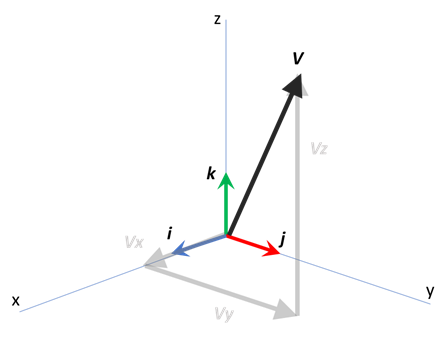

The vectors $\mathbf i,\mathbf j,\mathbf k$ are orthonormal and span $\mathbb R^3$. A vector space has infinitely many possible bases. Ordered orthonormal bases are related by orthogonal transformations over $\mathbb R$ and by unitary transformations over $\mathbb C$.

*The red, green, and blue arrows mark the Cartesian basis directions, while the gray vector is resolved into components along those axes.*


For a nonzero real vector $V$, let $\alpha,\beta,\gamma$ be its direction angles relative to the Cartesian axes. Then

$$
V_x=\|V\|\cos\alpha,\qquad
V_y=\|V\|\cos\beta,\qquad
V_z=\|V\|\cos\gamma,
$$

and $\cos^2\alpha+\cos^2\beta+\cos^2\gamma=1$. The Euclidean dot product is $V\cdot B=V_xB_x+V_yB_y+V_zB_z$. For complex vectors, replace this bilinear dot product with the conjugating inner product $V^\dagger B$.


### Outer products and tensor products of columns

The tensor product $A\otimes B$ of two column vectors is another column vector. The **outer product** is the matrix

$$
|A\rangle\langle B|=AB^\dagger,
\qquad (AB^\dagger)_{ij}=A_iB_j^*.
$$

For real vectors this reduces to $AB^T$. Outer products define projectors and matrix units; tensor products define composite spaces. Although the constructions are related abstractly, their array shapes and uses are different.


## Constructing an orthonormal basis

Gram–Schmidt replaces independent vectors $v_1,\ldots,v_k$ by orthonormal vectors spanning the same subspace:

$$
u_j=v_j-\sum_{i<j}\langle e_i|v_j\rangle e_i,
\qquad e_j=\frac{u_j}{\|u_j\|}.
$$

Numerically, a QR factorization is usually more stable than a hand-written classical Gram–Schmidt loop. The columns of $Q$ are orthonormal and span the columns of the input matrix.


In [12]:
V = np.array([[1, 1], [1j, 1], [0, 1j]], dtype=complex)
Q, R = np.linalg.qr(V)

print("Q†Q =")
print(np.round(Q.conj().T @ Q, 12))
print("same column-space projector:", np.allclose(Q @ Q.conj().T @ V, V))

Q†Q =
[[ 1.+0.j -0.-0.j]
 [-0.+0.j  1.+0.j]]
same column-space projector: True


## Matrices and matrix operations


### Algebraic rules

For equally shaped matrices, addition is associative and commutative, and scalar multiplication distributes:

$$
A+B=B+A,\quad (A+B)+C=A+(B+C),\quad
c(A+B)=cA+cB,\quad (c+d)A=cA+dA.
$$

When dimensions are compatible, matrix multiplication is associative and distributive,

$$
A(BC)=(AB)C,\quad A(B+C)=AB+AC,
$$

but it is generally not commutative: $AB\neq BA$.


NumPy distinguishes element-wise multiplication (`A * B`) from matrix multiplication (`A @ B`). SymPy matrices use `*` and `@` for matrix multiplication; explicit `multiply_elementwise` performs the Hadamard product.


In [13]:
A = np.array([[1, 2, 3], [4, 5, 6]])
B = np.array([[7, 8], [9, 10], [11, 12]])
display(A, B)

array([[1, 2, 3],
       [4, 5, 6]])

array([[ 7,  8],
       [ 9, 10],
       [11, 12]])

In [14]:
A*B.transpose() # this is Hadamard elementwise product

array([[ 7, 18, 33],
       [32, 50, 72]])

Matrix multiplication sums over the shared index:

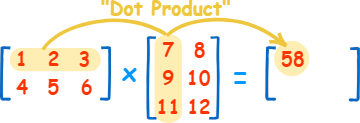

*The highlighted first row and first column are multiplied componentwise and summed to produce the displayed matrix entry 58.*


In [15]:
print(np.array([np.sum(A[0,:]*B[:,0])]))

[58]


In [16]:
MP = np.array([[np.sum(A[0,:]*B[:,0]), np.sum(A[0,:]*B[:,1])], [np.sum(A[1,:]*B[:,0]), np.sum(A[1,:]*B[:,1])]])

print(MP)

[[ 58  64]
 [139 154]]


In [17]:
A@B # this is matrix product

array([[ 58,  64],
       [139, 154]])

### SymPy demonstration


In [18]:
a, b, c, d, e, f, g, h = sy.symbols('a b c d e f g h', real=True)

In [19]:
A_sy = sy.Matrix([[a, b], [c, d]])
B_sy = sy.Matrix([[e, f], [g, h]])

display(A_sy, B_sy, A_sy + B_sy, A_sy * B_sy, A_sy @ B_sy)

Matrix([
[a, b],
[c, d]])

Matrix([
[e, f],
[g, h]])

Matrix([
[a + e, b + f],
[c + g, d + h]])

Matrix([
[a*e + b*g, a*f + b*h],
[c*e + d*g, c*f + d*h]])

Matrix([
[a*e + b*g, a*f + b*h],
[c*e + d*g, c*f + d*h]])

The **commutator** of two operators is

$$
[A,B]=AB-BA.
$$

It is zero exactly when the two operators commute.


In [20]:
commutator = A_sy * B_sy - B_sy * A_sy
display(commutator)

Matrix([
[             b*g - c*f, a*f - b*e + b*h - d*f],
[-a*g + c*e - c*h + d*g,            -b*g + c*f]])

The symbolic matrices commute if and only if every entry of the displayed commutator is zero. The first and fourth equations are negatives of each other, so only three of the four scalar constraints are independent.


In [21]:
C11, C12, C21, C22, A11, A12, A21, A22 = sy.symbols('C_{11}, C_{12}, C_{21}, C_{22}, A_{11}, A_{12}, A_{21}, A_{22}')

In [22]:
C = sy.Matrix([[C11, C12], [C21, C22]])
A = sy.Matrix([[A11, A12], [A21, A22]])
display(C, A)

Matrix([
[C_{11}, C_{12}],
[C_{21}, C_{22}]])

Matrix([
[A_{11}, A_{12}],
[A_{21}, A_{22}]])

### Determinants


In [23]:
C.det()

C_{11}*C_{22} - C_{12}*C_{21}

### Transposes


In [24]:
transpose_C = C.T
display(transpose_C)
print("C.T equals C.transpose():", transpose_C == C.transpose())

Matrix([
[C_{11}, C_{21}],
[C_{12}, C_{22}]])

C.T equals C.transpose(): True


In [25]:
# NumPy
rng_matrix = np.random.default_rng(9)
C_np = np.rint(rng_matrix.normal(size=(2, 2)))
print(C_np)
print(C_np.T)

[[-1.  0.]
 [-2.  1.]]
[[-1. -2.]
 [ 0.  1.]]


The transpose of a product reverses the order of the factors: $(CA)^T=A^TC^T$.


In [26]:
sy.simplify((C * A).T - A.T * C.T)

Matrix([
[0, 0],
[0, 0]])

## Projectors and the resolution of identity

For a normalized vector $u$, the rank-one operator

$$
P_u=|u\rangle\langle u|
$$

is Hermitian and idempotent: $P_u^\dagger=P_u$ and $P_u^2=P_u$. It extracts the component parallel to $u$. If $\{e_i\}$ is a complete orthonormal basis, then

$$
\sum_i |e_i\rangle\langle e_i|=I.
$$


In [27]:
u = np.array([1, 1j], dtype=complex) / np.sqrt(2)
P_u = np.outer(u, u.conj())

print("Hermitian:", np.allclose(P_u, P_u.conj().T))
print("idempotent:", np.allclose(P_u @ P_u, P_u))
print("eigenvalues:", np.linalg.eigvalsh(P_u))

Hermitian: True
idempotent: True
eigenvalues: [0. 1.]


### Inverse matrices


For a square invertible matrix $C$,

$$
CC^{-1}=C^{-1}C=I.
$$

An inverse exists exactly when $\det C\neq0$.


In [28]:
C.inv()

Matrix([
[ C_{22}/(C_{11}*C_{22} - C_{12}*C_{21}), -C_{12}/(C_{11}*C_{22} - C_{12}*C_{21})],
[-C_{21}/(C_{11}*C_{22} - C_{12}*C_{21}),  C_{11}/(C_{11}*C_{22} - C_{12}*C_{21})]])

NumPy provides <code>np.linalg.inv</code> for computing the inverse of a square, nonsingular array.


In [29]:
rng = np.random.default_rng(12)
C_np = rng.normal(size=(2, 2))
print(C_np)
print(np.linalg.inv(C_np))
print("inverse check:", np.allclose(C_np @ np.linalg.inv(C_np), np.eye(2)))

[[-0.00682678  1.04614329]
 [ 0.74158842  0.72395654]]
[[-0.92725777  1.33992089]
 [ 0.94984102  0.00874387]]
inverse check: True


Two properties of inverse matrices are used often:

1. If $A$ and $B$ are both invertible, then $(AB)^{-1}=B^{-1}A^{-1}$.
2. If $A$ is invertible, then $(A^T)^{-1}=(A^{-1})^T$.


### Solving a linear system

Consider

$$
\begin{aligned}
x+3y-7z&=18,\\
6x+2y+15z&=34,\\
-2x+3y-5z&=2.
\end{aligned}
$$

Writing $AX=b$ gives

$$
A=\begin{bmatrix}1&3&-7\\6&2&15\\-2&3&-5\end{bmatrix},\quad
X=\begin{bmatrix}x\\y\\z\end{bmatrix},\quad
b=\begin{bmatrix}18\\34\\2\end{bmatrix}.
$$

If $A$ is invertible, $X=A^{-1}b$. In numerical work, `np.linalg.solve(A, b)` is more accurate and efficient than explicitly forming the inverse.


In [30]:
A_system = np.array([[1, 3, -7], [6, 2, 15], [-2, 3, -5]], dtype=float)
b_system = np.array([18, 34, 2], dtype=float)

solution = np.linalg.solve(A_system, b_system)
print(solution)
print("residual:", A_system @ solution - b_system)

[ 5.14832536  3.63636364 -0.27751196]
residual: [ 3.55271368e-15  7.10542736e-15 -1.77635684e-15]


## Conditioning and numerical sensitivity

The singular values $\sigma_{\max}\geq\sigma_{\min}\geq0$ quantify how a matrix stretches vectors. For an invertible matrix, the 2-norm condition number is

$$
\kappa_2(A)=\frac{\sigma_{\max}}{\sigma_{\min}}.
$$

A large condition number means that small perturbations or rounding errors may cause a large relative change in the solution of $Ax=b$. Rank and condition number should therefore be interpreted with scale-aware numerical tolerances.


In [31]:
singular_values = np.linalg.svd(A_system, compute_uv=False)
condition_number = singular_values.max() / singular_values.min()

print("singular values:", singular_values)
print("condition number:", condition_number)

singular values: [18.13991632  5.31444728  2.16796818]
condition number: 8.367242876164916


### Complex conjugate matrices


In [32]:
# Complex conjugation

(1+2j).conjugate()

(1-2j)

In [33]:
x_complex = np.eye(2) + 1j * np.eye(2)
display(x_complex, x_complex.conjugate(), np.conjugate(x_complex))

array([[1.+1.j, 0.+0.j],
       [0.+0.j, 1.+1.j]])

array([[1.-1.j, 0.-0.j],
       [0.-0.j, 1.-1.j]])

array([[1.-1.j, 0.-0.j],
       [0.-0.j, 1.-1.j]])

### Adjoint and Hermitian matrices

The adjoint $A^\dagger=(A^*)^T$ is the conjugate transpose. A matrix is Hermitian when $A=A^\dagger$. A finite-dimensional Hermitian matrix has real eigenvalues and an orthonormal eigenbasis. Eigenvectors belonging to distinct eigenvalues are orthogonal; within a degenerate eigenspace, an orthonormal basis can be chosen.


In [34]:
x_array = np.arange(4).reshape(2, 2)
z_array = x_array - 1j * x_array

print(z_array)
print(z_array.conj().T)

[[0.+0.j 1.-1.j]
 [2.-2.j 3.-3.j]]
[[0.-0.j 2.+2.j]
 [1.+1.j 3.+3.j]]


In [35]:
C = sy.Matrix([[C11, C12], [C21, C22]])
display(C.H, C - C.H)

Matrix([
[conjugate(C_{11}), conjugate(C_{21})],
[conjugate(C_{12}), conjugate(C_{22})]])

Matrix([
[C_{11} - conjugate(C_{11}), C_{12} - conjugate(C_{21})],
[C_{21} - conjugate(C_{12}), C_{22} - conjugate(C_{22})]])

In [36]:
C_hermitian = sy.Matrix([[1, 1 + sy.I], [1 - sy.I, 4]])
display(C_hermitian)

Matrix([
[    1, 1 + I],
[1 - I,     4]])

In [37]:
sy.simplify(C_hermitian - C_hermitian.H)

Matrix([
[0, 0],
[0, 0]])

### Linear transformations


A matrix represents a linear transformation after bases have been chosen for its input and output spaces. Quantum gates are the norm-preserving, reversible subset represented by unitary matrices; general linear maps need not preserve normalized quantum states.


In [38]:
state = sy.Matrix([1, 0])
display(state)

Matrix([
[1],
[0]])

In [39]:
M = sy.Matrix([[1, 1 + 2 * sy.I], [1 - 2 * sy.I, 2]])
M_inv = M.inv()
display(M, M_inv)

Matrix([
[      1, 1 + 2*I],
[1 - 2*I,       2]])

Matrix([
[       -2/3, 1/3 + 2*I/3],
[1/3 - 2*I/3,        -1/3]])

In [40]:
new_state = M @ state
display(new_state)

Matrix([
[      1],
[1 - 2*I]])

In [41]:
sy.simplify(M_inv * new_state)

Matrix([
[1],
[0]])

## Spectral theorem preview

Every finite-dimensional Hermitian matrix has a decomposition

$$
H=\sum_k \lambda_k |v_k\rangle\langle v_k|
=V\,\mathrm{diag}(\lambda_k)V^\dagger,
$$

where the eigenvalues $\lambda_k$ are real and the eigenvectors form an orthonormal basis. `np.linalg.eigh` exploits Hermitian structure and should be preferred to the general `eig` routine for such matrices.


In [42]:
H_numeric = np.array([[2, 1 - 1j], [1 + 1j, 3]], dtype=complex)
eigenvalues, eigenvectors = np.linalg.eigh(H_numeric)
reconstructed = eigenvectors @ np.diag(eigenvalues) @ eigenvectors.conj().T

print("eigenvalues:", eigenvalues)
print("orthonormal eigenvectors:", np.allclose(eigenvectors.conj().T @ eigenvectors, np.eye(2)))
print("reconstruction:", np.allclose(reconstructed, H_numeric))

eigenvalues: [1. 4.]
orthonormal eigenvectors: True
reconstruction: True


## Key takeaways

- Quantum states live in complex vector spaces with the inner product $\langle u|v\rangle=u^\dagger v$.
- An orthonormal basis resolves vectors and the identity; a projector isolates a subspace.
- The tensor product constructs composite state spaces, whereas an outer product constructs an operator.
- Use algorithms that respect matrix structure, and inspect conditioning before trusting numerical digits.


## References and further reading

**Course-wide reference**

A. Krasnok, [*Introduction to Quantum Computing and Sensing for Electrical Engineers: A Hands-On Guide*](https://link.springer.com/book/9783032345295), *Synthesis Lectures on Emerging Engineering Technologies*, Springer, Cham, 1st ed., forthcoming September 2026, 403 pp. Hardcover ISBN 978-3-032-34529-5; eBook ISBN 978-3-032-34530-1.

1. G. Strang, [*Introduction to Linear Algebra* resources](https://math.mit.edu/~gs/linearalgebra/).
2. J. Watrous, [*The Theory of Quantum Information*](https://cs.uwaterloo.ca/~watrous/TQI/) (Cambridge University Press, 2018), Chapters 1–2.
3. M. A. Nielsen and I. L. Chuang, [*Quantum Computation and Quantum Information*](https://www.cambridge.org/highereducation/books/quantum-computation-and-quantum-information/01E10196D0A682A6AEFFEA52D53BE9AE), 10th anniversary edition, Sections 2.1–2.2.
4. [NumPy linear algebra reference](https://numpy.org/doc/stable/reference/routines.linalg.html), including [`vdot`](https://numpy.org/doc/stable/reference/generated/numpy.vdot.html) and [`eigh`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eigh.html).
5. [Qiskit quantum-information operators](https://quantum.cloud.ibm.com/docs/en/guides/operators-overview).
